# Phase 2: Exploratory data analysis

**Goal:** find out what the Olist data can support, as evidence for the seven problems in `docs/phase_02_eda.md`.

**Rule for this notebook:** coverage checks use all orders. Anything that involves a target (late deliveries, reviews, sales, seller activity) uses only orders before `HOLDOUT_START`, so the final test period stays unseen. No models are fitted here.

In [1]:
import sys
from pathlib import Path

# A notebook starts in notebooks/, so add the project root to import from src.
sys.path.insert(0, str(Path.cwd().parent))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.data.load import load_all

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {
        "figure.figsize": (9, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.grid.axis": "y",
        "grid.color": "#e6e5e0",
        "font.size": 10,
    }
)

tables = load_all()
orders = tables["orders"]
items = tables["order_items"]
payments = tables["order_payments"]
reviews = tables["order_reviews"]
customers = tables["customers"]
products = tables["products"]
sellers = tables["sellers"]
geolocation = tables["geolocation"]
translation = tables["category_translation"]

holdout_start = pd.Timestamp(config.HOLDOUT_START)

## 1. Coverage over time (all orders, no targets)

This shows which months are complete enough to use.

In [3]:
purchase_month = orders["order_purchase_timestamp"].dt.to_period("M")
coverage = pd.DataFrame(
    {
        "orders": orders.groupby(purchase_month).size(),
        "delivered_share": orders["order_status"].eq("delivered").groupby(purchase_month).mean(),
        "review_share": orders["order_id"].isin(reviews["order_id"]).groupby(purchase_month).mean(),
    }
)
coverage.round(3)

,orders,delivered_share,review_share
order_purchase_timestamp,,,
2016-09,4,0.250,1.000
2016-10,324,0.818,0.985
2016-12,1,1.000,1.000
2017-01,800,0.938,0.988
2017-02,1780,0.929,0.993
2017-03,2682,0.949,0.992
2017-04,2404,0.958,0.993
2017-05,3700,0.958,0.991
2017-06,3245,0.966,0.992


**Finding:** 2017-01 to 2018-08 is the usable range. 2016 is very thin, with no orders in November, and September and October 2018 have only 20 orders, none delivered.

## 2. Development set

Everything below uses orders before the holdout. Shared helpers build one row per order, so items and payments can't multiply rows.

In [4]:
development = orders[orders["order_purchase_timestamp"] < holdout_start].copy()
assert development["order_purchase_timestamp"].max() < holdout_start
print(f"Development orders: {len(development):,}")
print(f"Holdout orders: {len(orders) - len(development):,}")


def haversine_km(lat1, lng1, lat2, lng2):
    """Return the great-circle distance in kilometres."""
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    )
    return 6371 * 2 * np.arcsin(np.sqrt(a))


# A zip prefix has many coordinates, so use the median of each.
zip_coords = geolocation.groupby("geolocation_zip_code_prefix")[
    ["geolocation_lat", "geolocation_lng"]
].median()
zip_coords.columns = ["lat", "lng"]

item_summary = items.groupby("order_id").agg(
    n_items=("order_item_id", "size"),
    n_sellers=("seller_id", "nunique"),
    item_total=("price", "sum"),
)
first_item = items.sort_values("order_item_id").drop_duplicates("order_id")[
    ["order_id", "seller_id", "product_id"]
]

delivered = development[
    development["order_status"].eq("delivered")
    & development["order_delivered_customer_date"].notna()
].copy()
purchase = delivered["order_purchase_timestamp"]
actual = delivered["order_delivered_customer_date"]
promised = delivered["order_estimated_delivery_date"]
delivered["is_late"] = actual.dt.normalize() > promised
delivered["days_actual"] = (actual - purchase).dt.total_seconds() / 86400
delivered["days_promised"] = (promised - purchase).dt.total_seconds() / 86400
delivered["days_margin"] = delivered["days_promised"] - delivered["days_actual"]

delivered = (
    delivered.merge(item_summary, on="order_id", how="left")
    .merge(first_item, on="order_id", how="left")
    .merge(
        customers[["customer_id", "customer_state", "customer_zip_code_prefix"]],
        on="customer_id",
        how="left",
    )
    .merge(
        sellers[["seller_id", "seller_state", "seller_zip_code_prefix"]],
        on="seller_id",
        how="left",
    )
    .join(zip_coords.add_prefix("customer_"), on="customer_zip_code_prefix")
    .join(zip_coords.add_prefix("seller_"), on="seller_zip_code_prefix")
)
delivered["distance_km"] = haversine_km(
    delivered["customer_lat"],
    delivered["customer_lng"],
    delivered["seller_lat"],
    delivered["seller_lng"],
)
assert delivered["order_id"].is_unique
print(f"Delivered orders: {len(delivered):,}, late rate: {delivered['is_late'].mean():.4f}")

Development orders: 80,450
Holdout orders: 18,991
Delivered orders: 77,867, late rate: 0.0753


## 3. Delivery delay

In [5]:
delivered["days_actual days_promised days_margin".split()].describe().round(2)

,days_actual,days_promised,days_margin
count,77867.00,77867.00,77867.00
mean,13.50,24.44,10.94
std,10.01,8.16,10.33
min,0.53,7.00,-188.98
25%,7.22,19.38,7.02
50%,11.18,23.53,12.02
75%,16.96,28.52,16.10
max,209.63,155.14,146.02


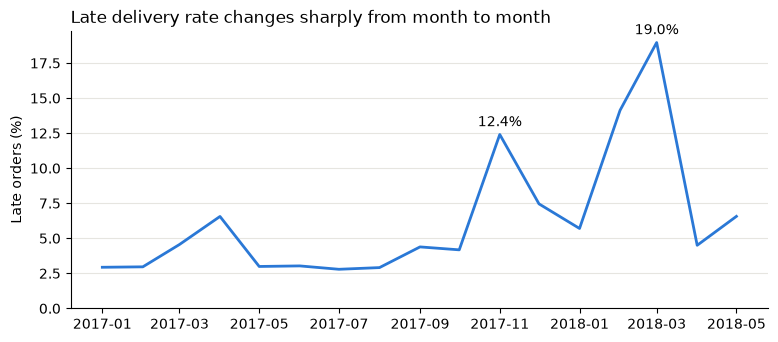

In [6]:
recent = delivered[delivered["order_purchase_timestamp"] >= "2017-01-01"]
month = recent["order_purchase_timestamp"].dt.to_period("M")
monthly_late = recent.groupby(month)["is_late"].mean() * 100

fig, ax = plt.subplots()
ax.plot(monthly_late.index.to_timestamp(), monthly_late.values, color=BLUE, linewidth=2)
ax.set_title("Late delivery rate changes sharply from month to month", loc="left")
ax.set_ylabel("Late orders (%)")
ax.set_ylim(bottom=0)
for label in ("2017-11", "2018-03"):
    period = pd.Period(label)
    ax.annotate(
        f"{monthly_late[period]:.1f}%",
        (period.to_timestamp(), monthly_late[period]),
        textcoords="offset points",
        xytext=(0, 6),
        ha="center",
    )
plt.show()

In [7]:
distance_group = pd.qcut(delivered["distance_km"], 5)
by_distance = delivered.groupby(distance_group, observed=True).agg(
    orders=("is_late", "size"),
    late_rate=("is_late", "mean"),
    median_days=("days_actual", "median"),
)
same_state = delivered["customer_state"].eq(delivered["seller_state"])
display(by_distance.round(3))
display(delivered.groupby(same_state)["is_late"].agg(["size", "mean"]).round(3))

by_state = delivered.groupby("customer_state")["is_late"].agg(["size", "mean"])
by_state[by_state["size"] >= 300].sort_values("mean", ascending=False).round(3)

,orders,late_rate,median_days
distance_km,,,
"(-0.001, 127.469]",15494,0.039,5.672
"(127.469, 352.114]",15493,0.067,9.882
"(352.114, 537.743]",15494,0.076,11.210
"(537.743, 880.419]",15493,0.083,13.131
"(880.419, 8032.93]",15494,0.111,17.023


,size,mean
False,50689,0.093
True,27178,0.043


,size,mean
customer_state,,
AL,335,0.242
MA,608,0.183
CE,1068,0.164
RJ,10224,0.140
PI,395,0.139
BA,2654,0.139
PA,792,0.130
ES,1647,0.121
PB,410,0.120


In [8]:
delivered[["days_actual", "distance_km", "days_promised"]].corr(method="spearman").round(3)

,days_actual,distance_km,days_promised
days_actual,1.000,0.542,0.503
distance_km,0.542,1.000,0.642
days_promised,0.503,0.642,1.000


**Findings**
- Olist's promise is very cautious. The median order takes about 11 days against about 24 promised.
- Lateness depends strongly on the period, with spikes in November 2017 and February to March 2018, so random splits would hide this. Validation must move forward in time.
- Delivery time grows with distance, and distance is known at purchase.

## 4. Customer satisfaction

Keep one review per order, the most recently answered. Otherwise joins would count some orders twice.

In [9]:
dev_reviews = reviews[reviews["order_id"].isin(development["order_id"])]
scores_per_order = dev_reviews.groupby("order_id")["review_score"].nunique()
print(f"Review rows: {len(dev_reviews):,} for {dev_reviews['order_id'].nunique():,} orders")
print(f"Orders with conflicting scores: {(scores_per_order > 1).sum():,}")
print(f"Rows sharing a review_id: {dev_reviews.duplicated('review_id', keep=False).sum():,}")

latest_reviews = dev_reviews.sort_values("review_answer_timestamp").drop_duplicates(
    "order_id", keep="last"
)
reviewed = delivered.merge(
    latest_reviews[["order_id", "review_score", "review_creation_date"]], on="order_id"
)
reviewed["is_low"] = reviewed["review_score"] <= 2
assert reviewed["order_id"].is_unique

days_to_review = (
    reviewed["review_creation_date"] - reviewed["order_delivered_customer_date"]
).dt.total_seconds() / 86400
print(f"Reviewed delivered orders: {len(reviewed):,}, low rate: {reviewed['is_low'].mean():.4f}")
print(f"Median days from delivery to review creation: {days_to_review.median():.2f}")
delivery_day = reviewed["order_delivered_customer_date"].dt.normalize()
early_reviews = reviewed["review_creation_date"] < delivery_day
print(f"Reviews created before delivery day: {early_reviews.mean():.4f}")
print(f"Low reviews on on-time orders: {(~reviewed.loc[reviewed['is_low'], 'is_late']).mean():.4f}")
reviewed.groupby("is_late").agg(
    orders=("is_low", "size"), mean_score=("review_score", "mean"), low_rate=("is_low", "mean")
).round(3)

Review rows: 80,302 for 79,781 orders
Orders with conflicting scores: 197
Rows sharing a review_id: 1,440
Reviewed delivered orders: 77,304, low rate: 0.1354
Median days from delivery to review creation: 0.24
Reviews created before delivery day: 0.0591
Low reviews on on-time orders: 0.6489


,orders,mean_score,low_rate
is_late,,,
False,71579,4.272,0.095
True,5725,2.204,0.642


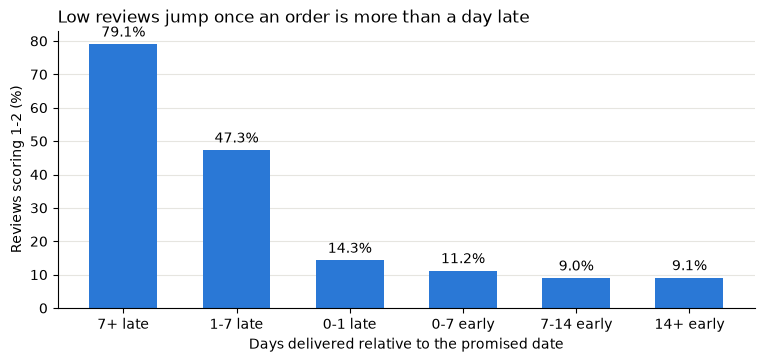

In [10]:
margin_group = pd.cut(
    reviewed["days_margin"],
    [-np.inf, -7, -1, 0, 7, 14, np.inf],
    labels=["7+ late", "1-7 late", "0-1 late", "0-7 early", "7-14 early", "14+ early"],
)
by_margin = reviewed.groupby(margin_group, observed=True)["is_low"].mean() * 100

fig, ax = plt.subplots()
bars = ax.bar(by_margin.index.astype(str), by_margin.values, color=BLUE, width=0.6)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_title("Low reviews jump once an order is more than a day late", loc="left")
ax.set_xlabel("Days delivered relative to the promised date")
ax.set_ylabel("Reviews scoring 1-2 (%)")
plt.show()

In [11]:
multi_item = reviewed["n_items"].clip(upper=3).rename("n_items_capped")
multi_seller = reviewed["n_sellers"].clip(upper=2).rename("n_sellers_capped")
for group in (multi_item, multi_seller):
    display(reviewed.groupby(group)["is_low"].agg(["size", "mean"]).round(3))

,size,mean
n_items_capped,,
1,69526,0.120
2,5978,0.259
3,1800,0.327


,size,mean
n_sellers_capped,,
1,76357,0.131
2,947,0.489


**Findings**
- Late orders get a low review about seven times as often as on-time orders.
- Lateness isn't the whole story: about 65% of low reviews are on on-time orders, and orders with several items or sellers score worse.
- Reviews are usually created within a day of delivery, so a prediction made at delivery leaves little time to act.

## 5. Sales

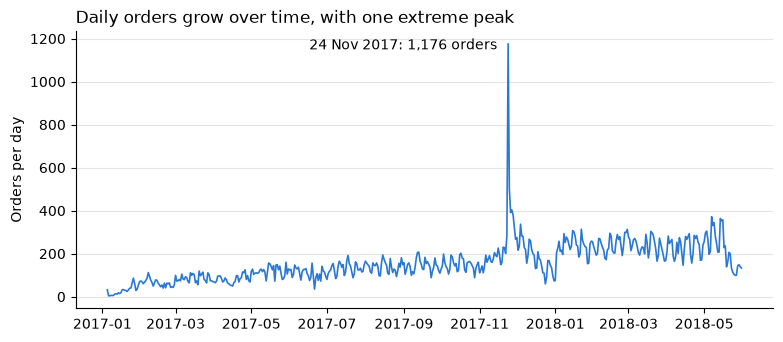

Days: 512, days with no orders: 0
Autocorrelation at lag 7: 0.655


order_purchase_timestamp
Friday       157.5
Monday       177.6
Saturday     120.4
Sunday       131.6
Thursday     161.0
Tuesday      175.9
Wednesday    171.4
dtype: float64

In [12]:
daily_orders = (
    development[development["order_purchase_timestamp"] >= "2017-01-01"]
    .set_index("order_purchase_timestamp")
    .resample("D")
    .size()
)
peak_day = daily_orders.idxmax()

fig, ax = plt.subplots()
ax.plot(daily_orders.index, daily_orders.values, color=BLUE, linewidth=1.2)
ax.annotate(
    f"{peak_day:%d %b %Y}: {daily_orders.max():,} orders",
    (peak_day, daily_orders.max()),
    textcoords="offset points",
    xytext=(-8, -4),
    ha="right",
)
ax.set_title("Daily orders grow over time, with one extreme peak", loc="left")
ax.set_ylabel("Orders per day")
plt.show()

print(f"Days: {len(daily_orders)}, days with no orders: {(daily_orders == 0).sum()}")
print("Autocorrelation at lag 7:", round(daily_orders.autocorr(7), 3))
daily_orders.groupby(daily_orders.index.day_name()).mean().round(1)

**Findings**
- There's a clear upward trend and a weekly pattern, with fewer orders on weekends.
- 24 November 2017 is an extreme one-off, and the data contains only one such peak. Forecasts need a holiday flag, not a learned yearly pattern.

## 6. Candidates for the other four problems

In [13]:
dev_items = items.merge(development[["order_id", "order_purchase_timestamp"]], on="order_id").merge(
    products, on="product_id", how="left"
)
dev_items = dev_items.merge(translation, on="product_category_name", how="left")
dev_items = dev_items[dev_items["order_purchase_timestamp"] >= "2017-01-01"]

category_items = dev_items["product_category_name_english"].value_counts()
top_categories = category_items.head(10)
print(f"Top 10 categories' share of items: {top_categories.sum() / category_items.sum():.3f}")
weekly_category = (
    dev_items[dev_items["product_category_name_english"].isin(top_categories.index)]
    .set_index("order_purchase_timestamp")
    .groupby("product_category_name_english")
    .resample("W")
    .size()
    .unstack(0)
    .fillna(0)
)
weekly_category.mean().sort_values(ascending=False).round(1)

Top 10 categories' share of items: 0.648


product_category_name_english
bed_bath_table           122.3
sports_leisure            98.0
health_beauty             96.0
furniture_decor           94.4
computers_accessories     88.5
housewares                69.8
watches_gifts             61.6
garden_tools              51.9
telephony                 51.5
toys                      48.3
dtype: float64

In [14]:
seller_items = items.merge(development[["order_id", "order_purchase_timestamp"]], on="order_id")
seller_summary = seller_items.groupby("seller_id").agg(
    orders=("order_id", "nunique"),
    revenue=("price", "sum"),
    last_sale=("order_purchase_timestamp", "max"),
)
top_decile = seller_summary["revenue"].nlargest(len(seller_summary) // 10).sum()
inactive_60 = (holdout_start - seller_summary["last_sale"]).dt.days > 60
print(f"Sellers: {len(seller_summary):,}")
print(f"Revenue from the top 10% of sellers: {top_decile / seller_summary['revenue'].sum():.3f}")
print(f"Median orders per seller: {seller_summary['orders'].median():.0f}")
print(f"No sale in the 60 days before the holdout: {inactive_60.mean():.3f}")

Sellers: 2,559
Revenue from the top 10% of sellers: 0.667
Median orders per seller: 6
No sale in the 60 days before the holdout: 0.444


In [15]:
freight = (
    items.merge(development[["order_id", "customer_id"]], on="order_id")
    .merge(customers[["customer_id", "customer_zip_code_prefix"]], on="customer_id")
    .merge(sellers[["seller_id", "seller_zip_code_prefix"]], on="seller_id")
    .merge(products, on="product_id")
    .join(zip_coords.add_prefix("customer_"), on="customer_zip_code_prefix")
    .join(zip_coords.add_prefix("seller_"), on="seller_zip_code_prefix")
)
freight["distance_km"] = haversine_km(
    freight["customer_lat"], freight["customer_lng"], freight["seller_lat"], freight["seller_lng"]
)
print(f"Item rows: {len(freight):,}, zero freight: {freight['freight_value'].eq(0).mean():.4f}")
freight[["freight_value", "distance_km", "product_weight_g", "price"]].corr(method="spearman")[
    "freight_value"
].round(3)

Item rows: 91,231, zero freight: 0.0042


freight_value       1.000
distance_km         0.626
product_weight_g    0.447
price               0.429
Name: freight_value, dtype: float64

### Rejected candidates

In [16]:
customer_ids = customers[["customer_id", "customer_unique_id"]]
customer_orders = development.merge(customer_ids, on="customer_id").sort_values(
    "order_purchase_timestamp"
)
customer_orders["order_number"] = customer_orders.groupby("customer_unique_id").cumcount()
first_orders = customer_orders[customer_orders["order_number"] == 0]
second_orders = customer_orders[customer_orders["order_number"] == 1][
    ["customer_unique_id", "order_purchase_timestamp"]
].rename(columns={"order_purchase_timestamp": "second_order"})
return_table = first_orders.merge(second_orders, on="customer_unique_id", how="left")
days_to_return = (return_table["second_order"] - return_table["order_purchase_timestamp"]).dt.days
observed = return_table["order_purchase_timestamp"] < holdout_start - pd.Timedelta(days=90)
one_order_share = (customer_orders.groupby("customer_unique_id").size() == 1).mean()

cancelled = development["order_status"].isin(["canceled", "unavailable"])
units_sold = seller_items.groupby("product_id").size()

print(f"Repeat within 90 days: {(days_to_return[observed] <= 90).sum():,} of {observed.sum():,}")
print(f"Customers with one order: {one_order_share:.3f}")
print(f"Cancelled or unavailable: {cancelled.sum():,} ({cancelled.mean():.4f})")
print(f"Products sold only once: {(units_sold == 1).mean():.3f}")

Repeat within 90 days: 1,478 of 58,033
Customers with one order: 0.970
Cancelled or unavailable: 1,043 (0.0130)
Products sold only once: 0.548


**Findings**
- **Keep:** category demand, seller activity, and freight cost have enough data and clear patterns.
- **Reject:** repeat purchase and customer segmentation (nearly every customer has one order), cancellation (few cases, and no cancellation timestamp to set a prediction moment), and product recommendation (over half of products sold once).